# Support Vector Machines Lab

## Introduction

Imagine you are a junior data scientist working at a botanical research institute. Your team is developing an automated plant classification system to assist researchers and horticulturists in identifying different plant species based on their morphological traits. The institute has collected a dataset containing measurements of various flower features, such as sepal length, sepal width, petal length, and petal width. Your goal is to create a machine learning model that can accurately classify flowers into different species based on these features.

To tackle this challenge, you will use the Iris dataset, a well-known dataset in machine learning that contains measurements of three species of iris flowers: Setosa, Versicolor, and Virginica.

## Problem-Solving Process

To build an effective species classification model, you will follow these key steps:
- **Data Collection & Preprocessing:** Load the Iris dataset, explore its structure, check for missing values, and standardize numerical features to ensure consistent training across models.
- **Feature Engineering:** Identify which features contribute most to distinguishing between different iris species.
- **Model Selection & Training:** Implement a Support Vector Machine (SVM) classifier, train it on labeled flower measurements, and optimize its parameters.
- **Evaluation & Interpretation:** Assess the model's performance using classification metrics such as accuracy, confusion matrix, classification report, and ROC curve to determine how well it differentiates between species.

## Challenge to Address

Manually classifying flowers based on visual inspection can be time-consuming and prone to human error. By applying machine learning techniques, specifically Support Vector Machines (SVMs), researchers can automate species classification with high accuracy, helping botanists, ecologists, and agricultural scientists analyze plant diversity more efficiently and make data-driven decisions in conservation and research.

This lab provides you with real-world skills in data preprocessing, machine learning model training, and model evaluation, all essential for solving classification problems in biological sciences and beyond.

### Step 0: Import Libraries

In [1]:
# CodeGrade step0

# Import any useful libraries:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, auc
from sklearn.datasets import load_iris

### Step 1: Load and Preprocess the Data

- Load the Iris dataset (code is provided below). Then view the first few rows and check for missing values. Next, visualize the relationship between the target variable (i.e. the iris type) and `sepal length (cm)`.
- Preprocess the data:
    - Encode the target variable as categorical.
    - Separate the features (X) and the target variable (y).
    - Standardize the numerical features.
    - Split the data (80%/20%), with `random_state = 42`.
    - Return the shapes (separated by commas) of `X_train`, `X_test`, `y_train`, and `y_test`.

In [2]:
# CodeGrade step0

# Load the Iris dataset:
iris = load_iris()
data = pd.DataFrame(iris.data, columns = iris.feature_names)
data["target"] = iris.target

In [3]:
# Print the first few rows of the dataset:
print(data.head())

# Check for missing values:
print("\nCheck missing values:")
print(data.isnull().sum())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

Check missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


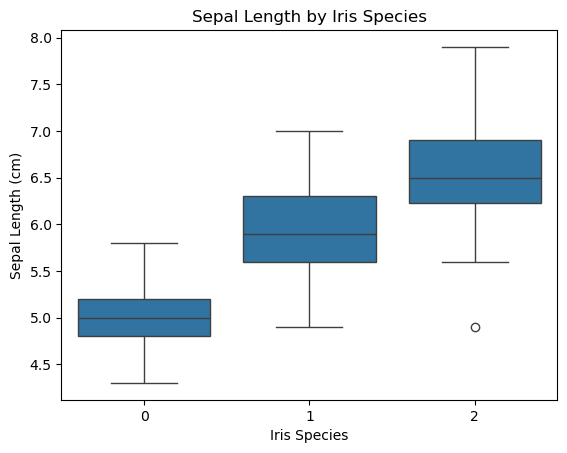

In [4]:
# Visualize the relationship between the target and `sepal length (cm)`:
sns.boxplot(data = data, x = "target", y = "sepal length (cm)")
plt.title("Sepal Length by Iris Species")
plt.xlabel("Iris Species")
plt.ylabel("Sepal Length (cm)")
plt.show()

In [5]:
# CodeGrade step1

# Encode the target variable as a categorical variable:
# The Iris dataset already represents the three species as 0, 1, and 2, so
# converting the dtype to `category` is sufficient (though also not strictly
# necessary, as the SVC classifier can handle integers as the category labels).
# No dummy encoding is necessary for the SVC classifier for this dataset.
data["target"] = data["target"].astype("category")

# Define the features (X) and the target variable (y):
# Select all columns except `target` as features:
X = data.drop(columns = "target")
# Use `target` as the target variable:
y = data["target"]

# Just like in the Module 2 lab, we should split the data BEFORE scaling it in
# order to prevent data leakage, even though the instructions seem to indicate
# scaling before splitting.
# Split the dataset into training (80%) and testing (20%) sets, with
# `random_state = 42`:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, 
                                                    random_state = 42)

# Scale the features:
scaler = StandardScaler()

# Fit the scaler on the training data only:
X_train_scaled = scaler.fit_transform(X_train)

# Use this same fitted scaler to transform the testing data:
X_test_scaled = scaler.transform(X_test)

# Return the shapes of the training and testing sets:
X_train_scaled.shape, X_test_scaled.shape, y_train.shape, y_test.shape

((120, 4), (30, 4), (120,), (30,))

### Step 2: Train the Model

- Initialize and train the SVC model.
- Find `y_pred` and `y_pred_proba`, and then return `y_pred`.

In [6]:
# CodeGrade step0

# Initialize the SVM classifier model with an RBF kernel:
svc_model = SVC(kernel = "rbf", probability = True)

# Train the model on the training data:
svc_model.fit(X_train_scaled, y_train)

/Users/briansilberman/miniforge3/envs/learn-env/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [7]:
# CodeGrade step2

# Predict the classes of the test data:
y_pred = svc_model.predict(X_test_scaled)

# Predict the probabilities of the test data:
y_pred_proba = svc_model.predict_proba(X_test_scaled)

# Return the test predictions:
y_pred

array([1, 0, 2, 1, 1, 0, 1, 2, 1, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0])

### Step 3: Confusion Matrix and Classification Report

- Return the confusion matrix.
- Print the classification report.

In [8]:
# CodeGrade step3

# Create a confusion matrix for the model:
cm = confusion_matrix(y_test, y_pred)

# Create a classification report for the model:
cr = classification_report(y_test, y_pred)

# Return the confusion matrix:
cm

array([[10,  0,  0],
       [ 0,  9,  0],
       [ 0,  0, 11]])

In [9]:
# Print the classification report:
print(cr)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00         9
           2       1.00      1.00      1.00        11

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



### Step 4: Best Parameters with Grid Search

- Optimize the model by running a grid search.
- Return the best parameters of the given model.

In [10]:
# CodeGrade step0

# Define a parameter grid for grid search:
param_grid = {"C": [0.1, 1, 10], 
              "gamma": [1, 0.1, 0.01, 0.001], 
              "kernel": ["rbf"]}

# Instantiate the grid search:
grid_search = GridSearchCV(SVC(probability = True), param_grid, cv = 5, 
                           scoring = "accuracy")

# Perform the grid search (fit it to the data):
grid_search.fit(X_train_scaled, y_train)

/Users/briansilberman/miniforge3/envs/learn-env/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/briansilberman/miniforge3/envs/learn-env/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/briansilberman/miniforge3/envs/learn-env/lib/python3.12/site-packages/sklearn/svm/_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/briansilberman/miniforge3/envs/learn-env/lib/python3.12/site-packa

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(probability=True)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': [1, 0.1, ...], 'kernel': ['rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informatio

In [11]:
# CodeGrade step4

# Get the best hyperparameters from the grid search:
grid_search.best_params_

{'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}

### Step 5: Prediction and Metrics

- For AUC:
    - Find `y_prob_optimized`.
    - Find `fpr`, `tpr`, and the `thresholds`.
    - Calculate the AUC and store it as `roc_auc`.
    - Return `roc_auc`.
- Finally, plot the ROC curve.

In [12]:
# CodeGrade step0

# Extract the optimized model from the grid search:
optimized_model = grid_search.best_estimator_

In [13]:
# CodeGrade step5

# Predict the optimized model's probabilities of the test data:
y_prob_optimized = optimized_model.predict_proba(X_test_scaled)

# Calculate the ROC curve:
# The `roc_curve()` function expects a binary classification target in
# `y_test`, but our dataset has three classes, 0, 1, and 2. Additionally, our
# probability array has three columns instead of two, one for each iris
# species. We will solve this by using one-vs.-rest ROC analysis. We will
# calculate a separate ROC curve for each species, where we treat that species
# as the positive class and the other two species as the negative class. Then
# we will calculate a single summary AUC score using a multiclass averaging
# method.
fpr = {}
tpr = {}
thresholds = {}

for i, class_label in enumerate(optimized_model.classes_):
    fpr[class_label], tpr[class_label], thresholds[class_label] = \
        roc_curve(y_test == class_label, y_prob_optimized[:, i])

# This is how to calculate the ROC curve for a binary classification model:
# fpr, tpr, thresholds = roc_curve(y_test, y_prob_optimized)

# Calculate the AUC (Area Under the Curve):
# We will calculate the AUC for multiclass models using one-vs.-rest analysis
# and macro averaging:
roc_auc = roc_auc_score(y_test, y_prob_optimized, multi_class = "ovr", 
                        average = "macro")

# This is how to calculate the AUC for a binary classification model:
# roc_auc = roc_auc_score(y_test, y_prob_optimized)

# Return `roc_auc`:
roc_auc

1.0

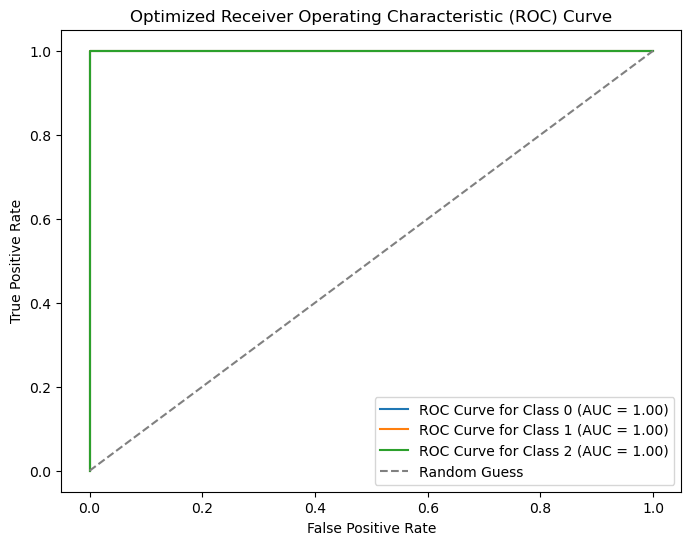

In [14]:
# Plot each species's ROC curve:
plt.figure(figsize = (8, 6))
for class_label in optimized_model.classes_:
    class_auc = auc(fpr[class_label], tpr[class_label])
    plt.plot(fpr[class_label], tpr[class_label], label = 
             f"ROC Curve for Class {class_label} (AUC = {class_auc:.2f})")
# This is how to plot one ROC curve for a binary classification model:
# plt.plot(fpr, tpr, label = f"ROC Curve (AUC = {roc_auc:.2f})")
# Add a reference line for random guessing:
plt.plot([0, 1], [0, 1], linestyle = "--", color = "gray", label = 
         "Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Optimized Receiver Operating Characteristic (ROC) Curve")
plt.legend()
plt.show()